In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (8, 4)

DATA = Path("csv_mania")          # <-- folder containing the Kaggle csv files
SAMPLE_N = 1_000_000         # rows used for join-heavy plots (section 6)
SEED = 42

Reading all the csv files


In [2]:
customers = pd.read_csv(DATA / "customers.csv")
articles  = pd.read_csv(DATA / "articles.csv")

# shared categorical dtype so joins/groupbys on customer_id are fast and light
cust_dtype = pd.CategoricalDtype(categories=customers["customer_id"].unique())
customers["customer_id"] = customers["customer_id"].astype(cust_dtype)

tx = pd.read_csv(
    DATA / "transactions_train.csv",
    dtype={"customer_id": cust_dtype, "article_id": "int32",
           "price": "float32", "sales_channel_id": "int8"},
    parse_dates=["t_dat"],
)
print(customers.shape, articles.shape, tx.shape)

(1371980, 7) (105542, 25) (31788324, 5)


Looking at the dataset structure


In [3]:
def overview(df, name):
    out = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    print(f"== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols | "
          f"{df.memory_usage(deep=True).sum() / 1e6:,.0f} MB | duplicated rows: {df.duplicated().sum():,}")
    return out

overview(customers, "customers")
overview(articles, "articles")
overview(tx, "transactions")

== customers: 1,371,980 rows x 7 cols | 533 MB | duplicated rows: 0
== articles: 105,542 rows x 25 cols | 111 MB | duplicated rows: 0
== transactions: 31,788,324 rows x 5 cols | 856 MB | duplicated rows: 2,974,905


,dtype,n_missing,pct_missing,n_unique
t_dat,datetime64[us],0,0.0,734
customer_id,category,0,0.0,1362281
article_id,int32,0,0.0,104547
price,float32,0,0.0,9857
sales_channel_id,int8,0,0.0,2


In [4]:
print(overview(tx.sample(2_000_000, random_state=SEED), "transactions (2M-row sample for speed)"))
print("\nDate range:", tx["t_dat"].min().date(), "->", tx["t_dat"].max().date())
tx.head()

== transactions (2M-row sample for speed): 2,000,000 rows x 5 cols | 247 MB | duplicated rows: 15,211
                           dtype  n_missing  pct_missing  n_unique
t_dat             datetime64[us]          0          0.0       734
customer_id             category          0          0.0    684245
article_id                 int32          0          0.0     81391
price                    float32          0          0.0      5946
sales_channel_id            int8          0          0.0         2

Date range: 2018-09-20 -> 2020-09-22


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [5]:
# Coverage / referential integrity
print("Customers with >=1 transaction:", f"{tx['customer_id'].nunique():,} / {len(customers):,}",
      f"({tx['customer_id'].nunique() / len(customers):.1%})")
print("Articles sold at least once  :", f"{tx['article_id'].nunique():,} / {len(articles):,}",
      f"({tx['article_id'].nunique() / len(articles):.1%})")
print("Transaction article_ids missing from articles.csv:", (~tx['article_id'].drop_duplicates().isin(articles['article_id'])).sum())

Customers with >=1 transaction: 1,362,281 / 1,371,980 (99.3%)
Articles sold at least once  : 104,547 / 105,542 (99.1%)
Transaction article_ids missing from articles.csv: 0


Working with customers csv


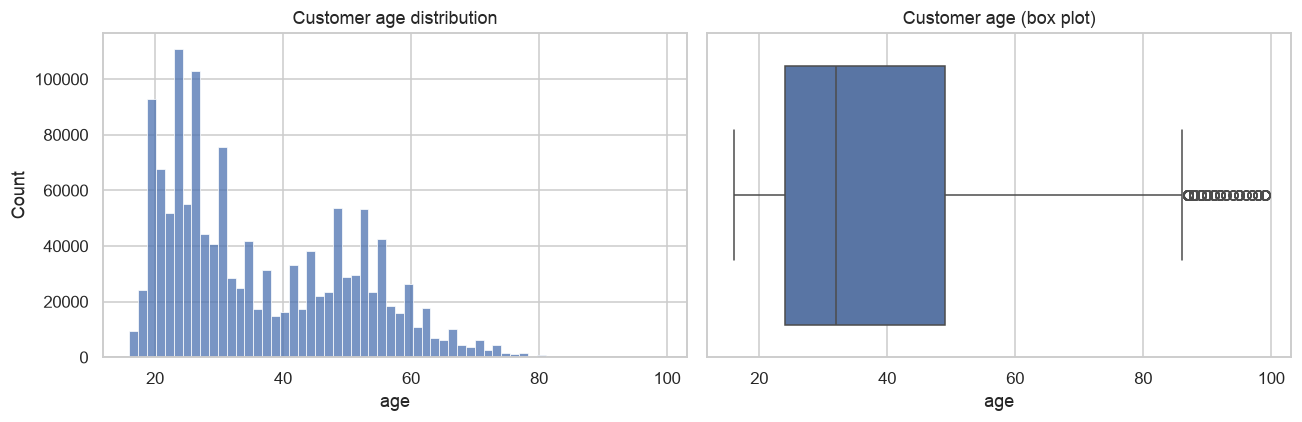

count    1356119.0
mean          36.4
std           14.3
min           16.0
25%           24.0
50%           32.0
75%           49.0
max           99.0
Name: age, dtype: float64

Age < 18: 9553 | Age > 80: 1112 | missing: 15861


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(customers["age"].dropna(), bins=60, ax=ax[0])
ax[0].set_title("Customer age distribution")
sns.boxplot(x=customers["age"].dropna(), ax=ax[1])
ax[1].set_title("Customer age (box plot)")
plt.tight_layout(); plt.show()

print(customers["age"].describe().round(1))
print("\nAge < 18:", (customers["age"] < 18).sum(), "| Age > 80:", (customers["age"] > 80).sum(),
      "| missing:", customers["age"].isna().sum())

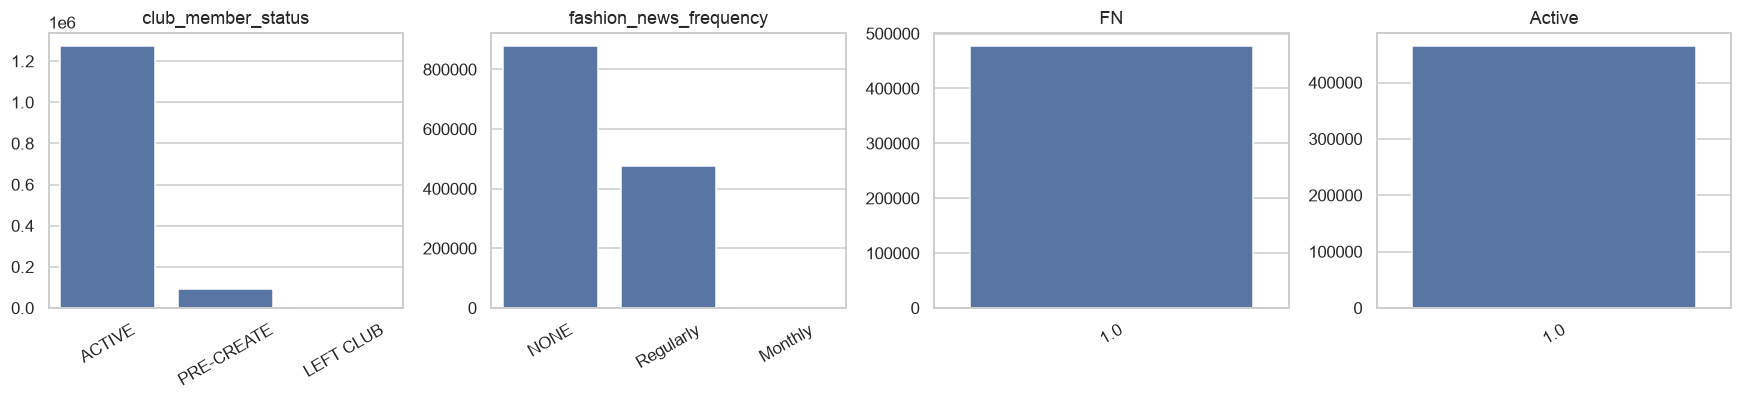

{'ACTIVE': 0.927, 'PRE-CREATE': 0.068, nan: 0.004, 'LEFT CLUB': 0.0}
{'NONE': 0.64, 'Regularly': 0.348, nan: 0.012, 'Monthly': 0.001}
{nan: 0.652, 1.0: 0.348}
{nan: 0.662, 1.0: 0.338}


In [7]:
# NOTE: dropna=False because the missing values are informative here
cat_cols = ["club_member_status", "fashion_news_frequency", "FN", "Active"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for a, c in zip(axes, cat_cols):
    vc = customers[c].value_counts(dropna=False)
    sns.barplot(x=vc.index.astype(str), y=vc.values, ax=a)
    a.set_title(c); a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

for c in cat_cols:
    print(customers[c].value_counts(dropna=False, normalize=True).round(3).to_dict())

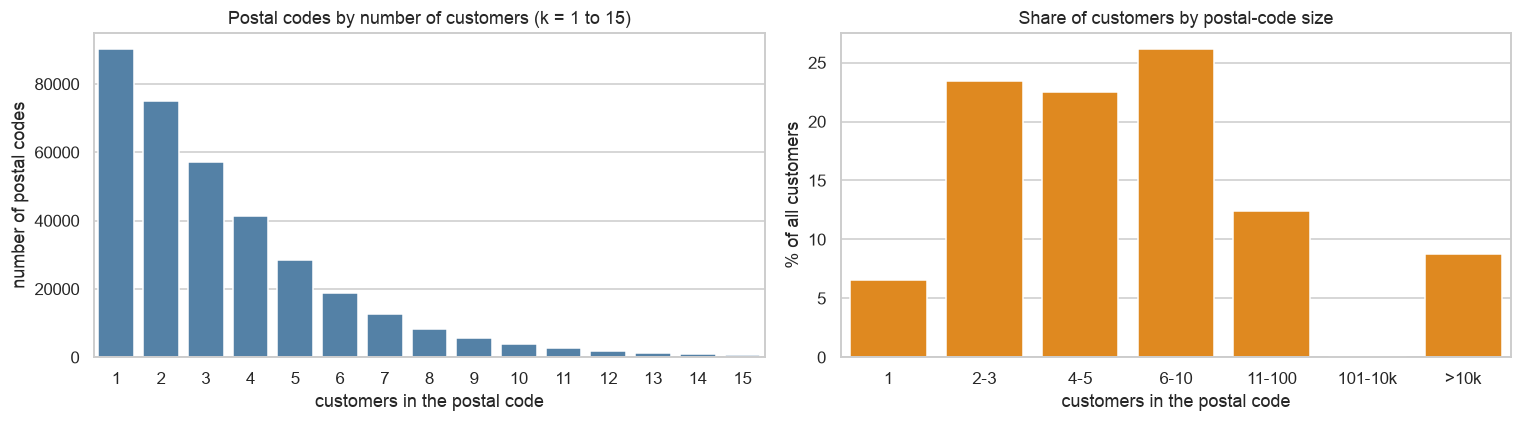

,n_postal_codes,n_customers,pct_customers
count,,,
1,90368,90368,6.6
2-3,132129,321487,23.4
4-5,69936,308316,22.5
6-10,49524,359407,26.2
11-100,10927,170132,12.4
101-10k,14,1967,0.1
>10k,1,120303,8.8


In [10]:
pc = customers["postal_code"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Left: how many postal codes have exactly k customers (k = 1..15)
cc = pc.value_counts().sort_index()
cc_small = cc[cc.index <= 15]
sns.barplot(x=cc_small.index, y=cc_small.values, ax=ax[0], color="steelblue")
ax[0].set_title("Postal codes by number of customers (k = 1 to 15)")
ax[0].set_xlabel("customers in the postal code"); ax[0].set_ylabel("number of postal codes")

# Right: where do the customers actually live? (share of customers per bucket)
bins   = [0, 1, 3, 5, 10, 100, 10_000, np.inf]
labels = ["1", "2-3", "4-5", "6-10", "11-100", "101-10k", ">10k"]
bucket = pd.cut(pc, bins=bins, labels=labels)
share = pc.groupby(bucket, observed=True).sum() / pc.sum()
sns.barplot(x=share.index.astype(str), y=share.values * 100, ax=ax[1], color="darkorange")
ax[1].set_title("Share of customers by postal-code size")
ax[1].set_xlabel("customers in the postal code"); ax[1].set_ylabel("% of all customers")

plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "n_postal_codes": pc.groupby(bucket, observed=True).size(),
    "n_customers": pc.groupby(bucket, observed=True).sum(),
})
summary["pct_customers"] = (summary["n_customers"] / pc.sum() * 100).round(1)
summary

working with articles.csv


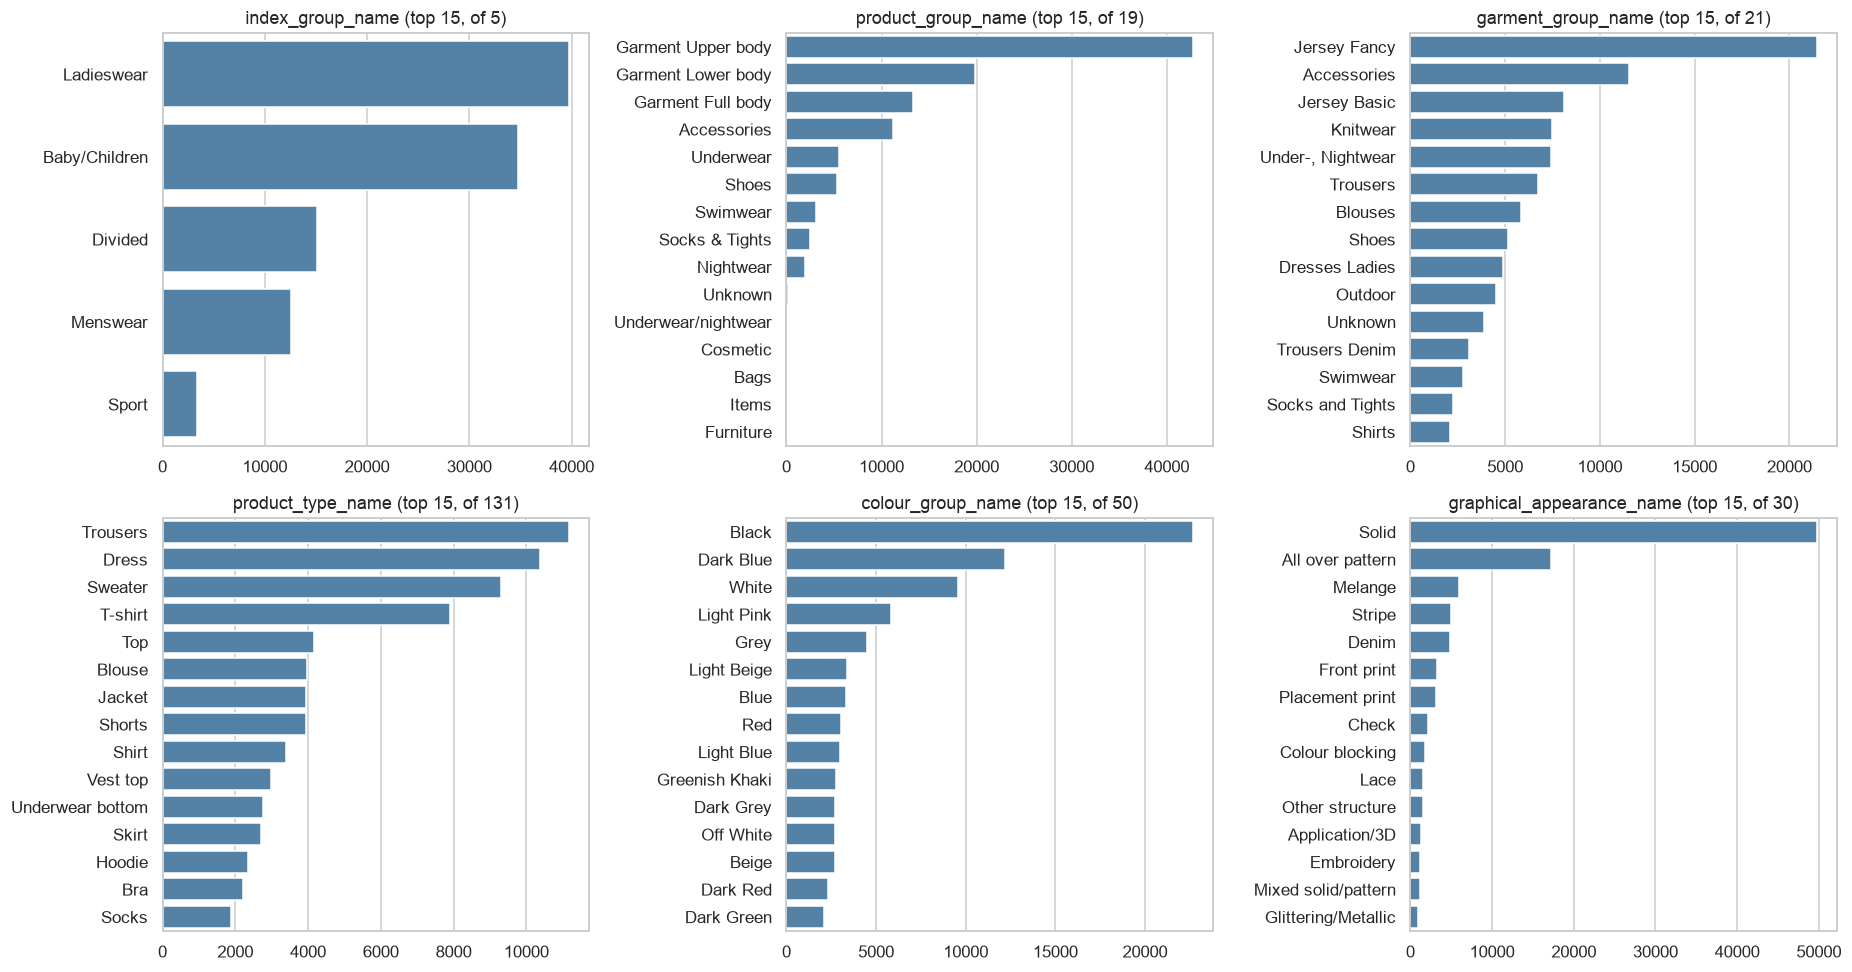

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for a, c in zip(axes.ravel(), ["index_group_name", "product_group_name", "garment_group_name",
                               "product_type_name", "colour_group_name", "graphical_appearance_name"]):
    vc = articles[c].value_counts().head(15)
    sns.barplot(x=vc.values, y=vc.index, ax=a, color="steelblue")
    a.set_title(f"{c} (top 15, of {articles[c].nunique()})"); a.set_ylabel("")
plt.tight_layout(); plt.show()


Missing detail_desc: 416


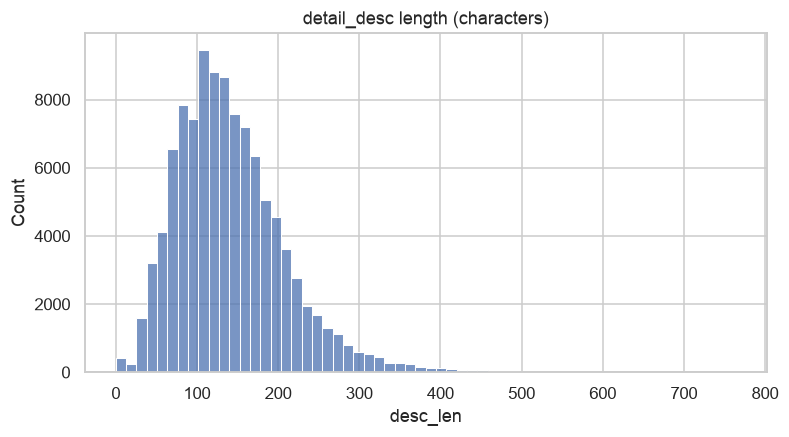

product_type                 unique codes= 132  unique names= 131
graphical_appearance         unique codes=  30  unique names=  30
colour_group                 unique codes=  50  unique names=  50
department                   unique codes= 299  unique names= 250
index                        unique codes=  10  unique names=  10
index_group                  unique codes=   5  unique names=   5
section                      unique codes=  57  unique names=  56
garment_group                unique codes=  21  unique names=  21


In [12]:
# Missing text + description length
print("Missing detail_desc:", articles["detail_desc"].isna().sum())
articles["desc_len"] = articles["detail_desc"].fillna("").str.len()
sns.histplot(articles["desc_len"], bins=60); plt.title("detail_desc length (characters)"); plt.show()

# Redundant code/name column pairs (1:1 mapping => duplicated information)
pairs = [c[:-5] for c in articles.columns if c.endswith("_name") and (c[:-5] + "_no" in articles.columns or c[:-5] + "_code" in articles.columns)]
for p in pairs:
    code_col = p + "_no" if p + "_no" in articles.columns else p + "_code"
    print(f"{p:28s} unique codes={articles[code_col].nunique():4d}  unique names={articles[p + '_name'].nunique():4d}")

working with Transactions.csv


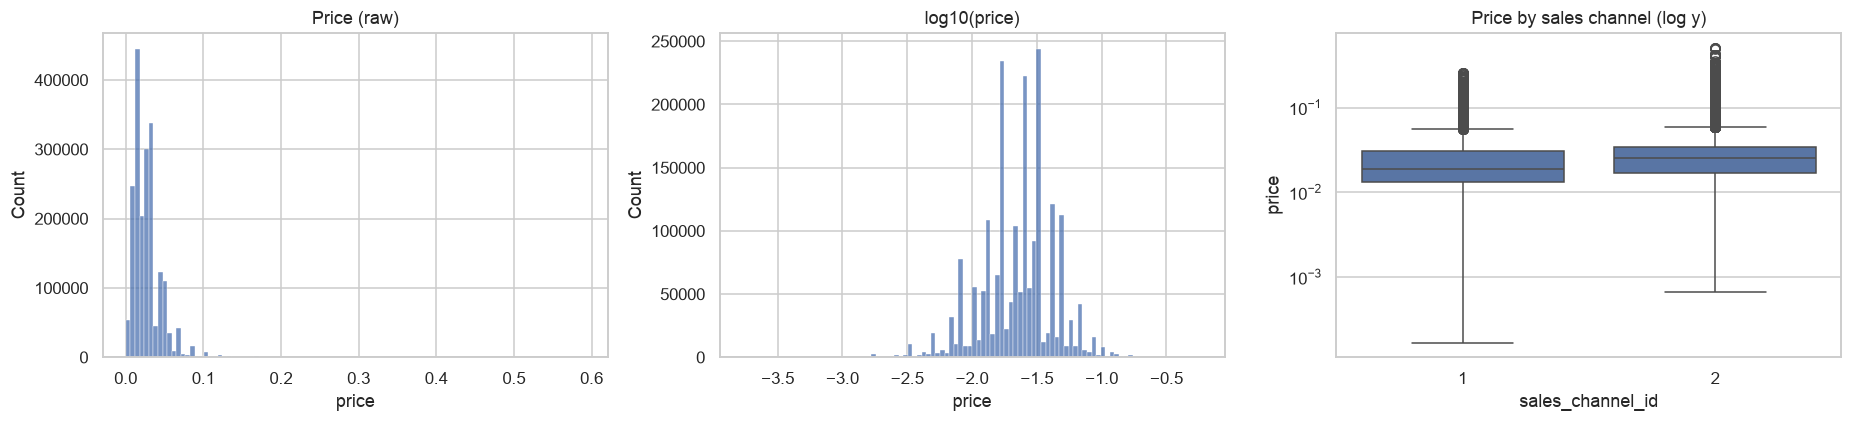

count    3.178832e+07
mean     2.780000e-02
std      1.920000e-02
min      0.000000e+00
25%      1.580000e-02
50%      2.540000e-02
75%      3.390000e-02
max      5.915000e-01
Name: price, dtype: float64

Sales channel share:
 sales_channel_id
2    0.704
1    0.296
Name: proportion, dtype: float64


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(tx["price"].sample(2_000_000, random_state=SEED), bins=100, ax=ax[0])
ax[0].set_title("Price (raw)")
sns.histplot(np.log10(tx["price"].sample(2_000_000, random_state=SEED)), bins=100, ax=ax[1])
ax[1].set_title("log10(price)")
sns.boxplot(data=tx.sample(1_000_000, random_state=SEED), x="sales_channel_id", y="price", ax=ax[2])
ax[2].set_yscale("log"); ax[2].set_title("Price by sales channel (log y)")
plt.tight_layout(); plt.show()

print(tx["price"].describe().round(4))
print("\nSales channel share:\n", tx["sales_channel_id"].value_counts(normalize=True).round(3))

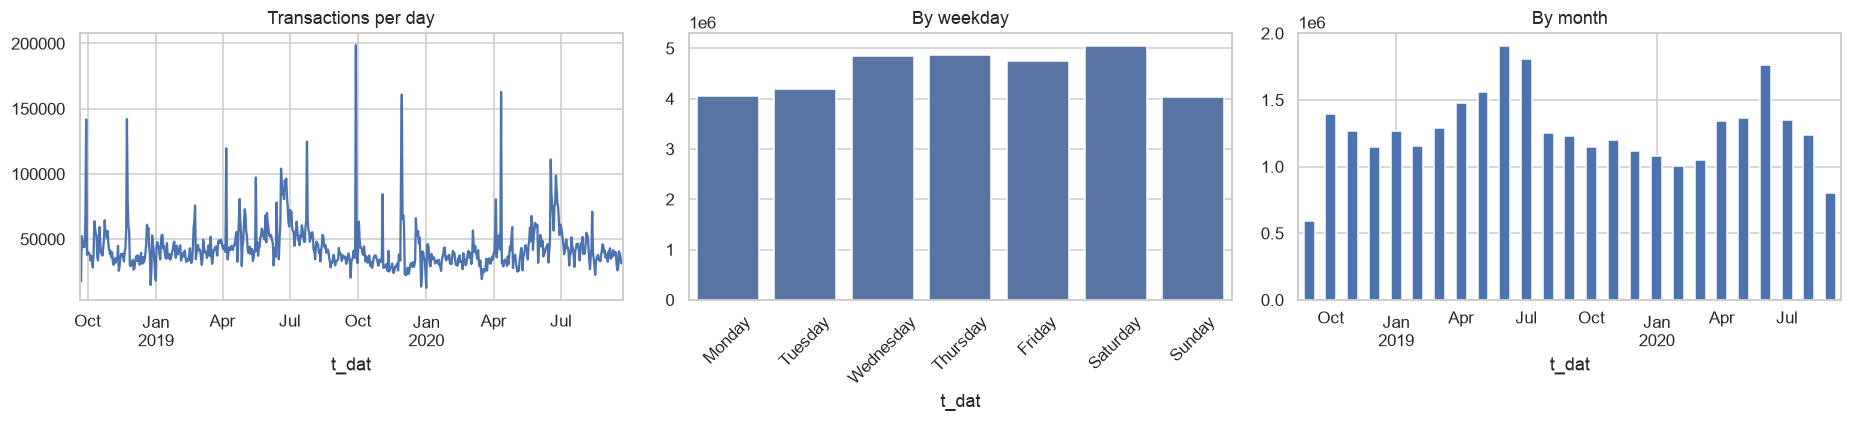

In [15]:
daily = tx.groupby("t_dat").size()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
daily.plot(ax=ax[0]); ax[0].set_title("Transactions per day")
dow = tx["t_dat"].dt.day_name().value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
sns.barplot(x=dow.index, y=dow.values, ax=ax[1]); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("By weekday")
tx.groupby(tx["t_dat"].dt.to_period("M")).size().plot(kind="bar", ax=ax[2]); ax[2].set_title("By month")
plt.tight_layout(); plt.show()

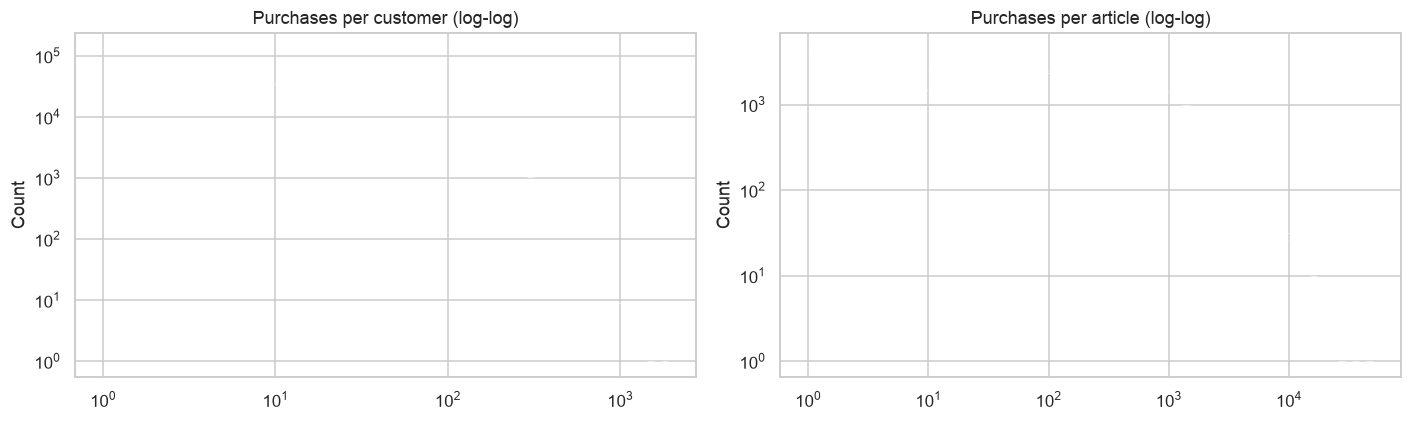

count    1362281.0
mean          23.3
std           39.2
min            1.0
25%            3.0
50%            9.0
75%           27.0
max         1895.0
dtype: float64

Customers with exactly 1 purchase: 9.7% | <=5 purchases: 36.8%


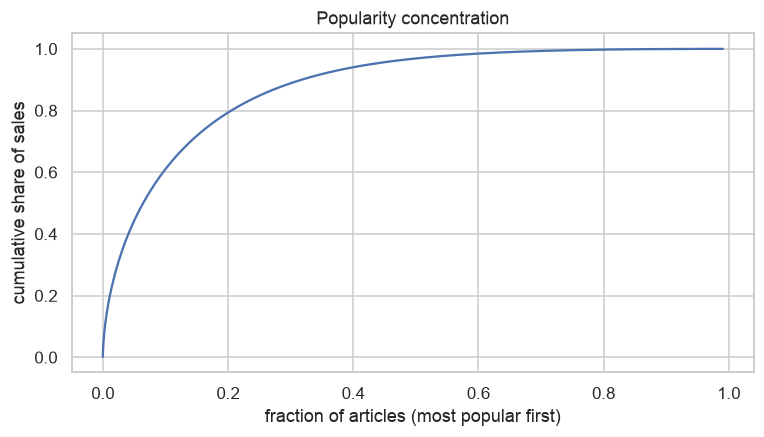

Top    100 articles = 4.6% of all transactions
Top  1,000 articles = 18.2% of all transactions
Top 10,000 articles = 59.6% of all transactions


In [16]:
# Long tails: purchases per customer and per article
per_cust = tx.groupby("customer_id", observed=True).size()
per_art  = tx.groupby("article_id").size()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(per_cust, bins=80, log_scale=(True, True), ax=ax[0]); ax[0].set_title("Purchases per customer (log-log)")
sns.histplot(per_art,  bins=80, log_scale=(True, True), ax=ax[1]); ax[1].set_title("Purchases per article (log-log)")
plt.tight_layout(); plt.show()

print(per_cust.describe().round(1))
print("\nCustomers with exactly 1 purchase:", f"{(per_cust == 1).mean():.1%}",
      "| <=5 purchases:", f"{(per_cust <= 5).mean():.1%}")

# Popularity concentration
s = per_art.sort_values(ascending=False)
cum = s.cumsum() / s.sum()
plt.plot(np.arange(1, len(cum) + 1) / len(articles), cum.values)
plt.xlabel("fraction of articles (most popular first)"); plt.ylabel("cumulative share of sales")
plt.title("Popularity concentration"); plt.show()
for k in (100, 1000, 10000):
    print(f"Top {k:>6,} articles = {cum.iloc[k-1]:.1%} of all transactions")

In [17]:
# Sparsity of the user-item matrix + repeat purchases (on a 5% customer subset to save memory)
n_cust, n_art = tx["customer_id"].nunique(), tx["article_id"].nunique()
pairs_n = len(tx[["customer_id", "article_id"]].drop_duplicates())
print(f"User-item matrix density: {pairs_n / (len(customers) * len(articles)):.5%}")

sub = tx[tx["customer_id"].cat.codes % 20 == 0]
dup_share = sub.duplicated(["customer_id", "article_id"]).mean()
print(f"Share of transactions that re-buy an article the customer already bought (5% subset): {dup_share:.1%}")

User-item matrix density: 0.01886%
Share of transactions that re-buy an article the customer already bought (5% subset): 14.3%


Testing random relationships and correlations between the files


1) Joining a random sample of transactions with customer and article attributes to create a relationship plot


In [18]:
df = (tx.sample(SAMPLE_N, random_state=SEED)
        .merge(customers, on="customer_id", how="left")
        .merge(articles.drop(columns="desc_len"), on="article_id", how="left"))
df["age_bin"] = pd.cut(df["age"], [0, 19, 24, 29, 34, 44, 54, 64, 100],
                       labels=["<20", "20-24", "25-29", "30-34", "35-44", "45-54", "55-64", "65+"])
df.shape

(1000000, 36)

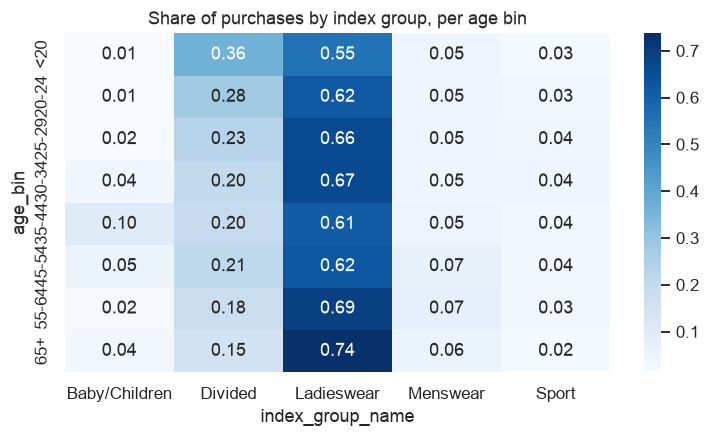

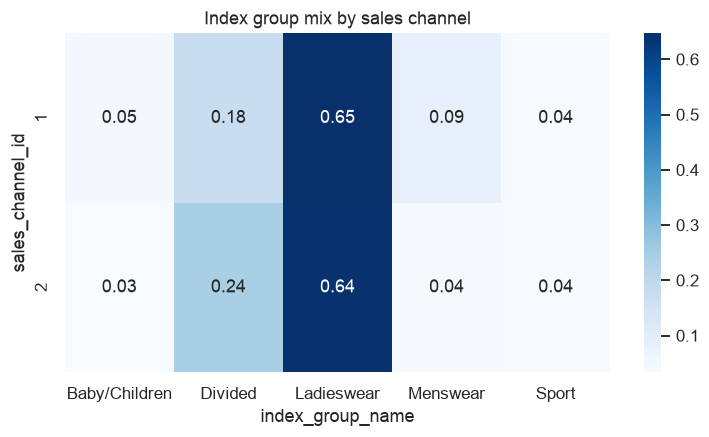

In [19]:
# 6a. What do different age groups buy? (row-normalised: each age bin sums to 1)
ct = pd.crosstab(df["age_bin"], df["index_group_name"], normalize="index")
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("Share of purchases by index group, per age bin"); plt.show()

ct2 = pd.crosstab(df["sales_channel_id"], df["index_group_name"], normalize="index")
sns.heatmap(ct2, annot=True, fmt=".2f", cmap="Blues"); plt.title("Index group mix by sales channel"); plt.show()

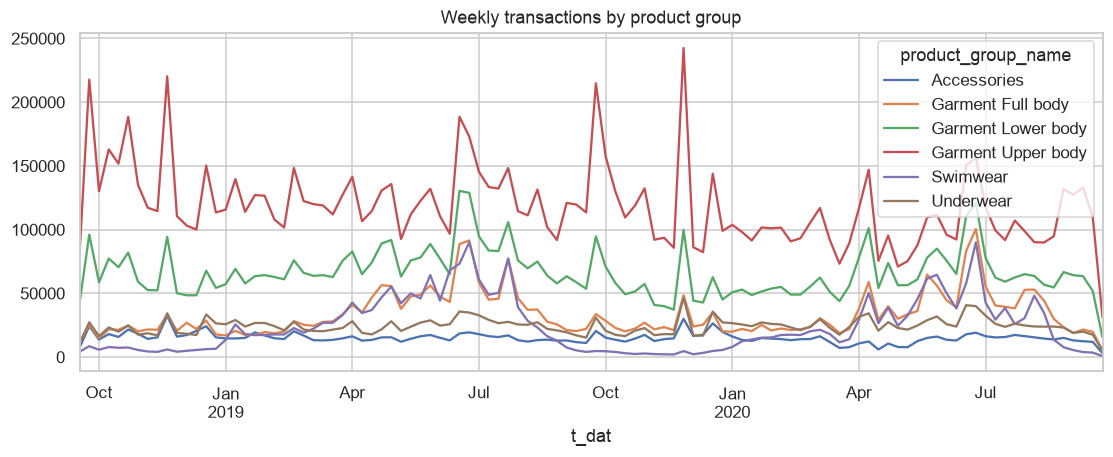

In [20]:
# 6b. Seasonality by product group (weekly sales, top 6 groups)
top = tx.merge(articles[["article_id", "product_group_name"]], on="article_id")
top_groups = top["product_group_name"].value_counts().head(6).index
wk = (top[top["product_group_name"].isin(top_groups)]
      .groupby([pd.Grouper(key="t_dat", freq="W"), "product_group_name"]).size().unstack())
wk.plot(figsize=(12, 4)); plt.title("Weekly transactions by product group"); plt.show()
del top

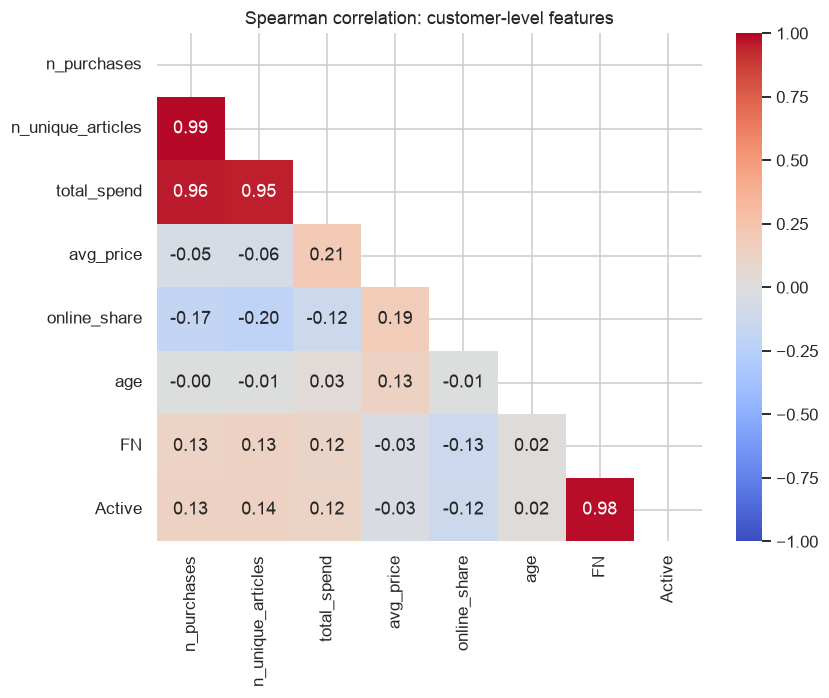

In [21]:
# 6c. Numeric correlation heatmap at the CUSTOMER level (Spearman: data is heavily skewed)
tx["is_online"] = (tx["sales_channel_id"] == 2).astype("int8")
agg = tx.groupby("customer_id", observed=True).agg(
    n_purchases=("article_id", "size"),
    n_unique_articles=("article_id", "nunique"),
    total_spend=("price", "sum"),
    avg_price=("price", "mean"),
    online_share=("is_online", "mean"),
)
agg = agg.join(customers.set_index("customer_id")[["age", "FN", "Active"]].fillna({"FN": 0, "Active": 0}))

corr = agg.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation: customer-level features"); plt.show()

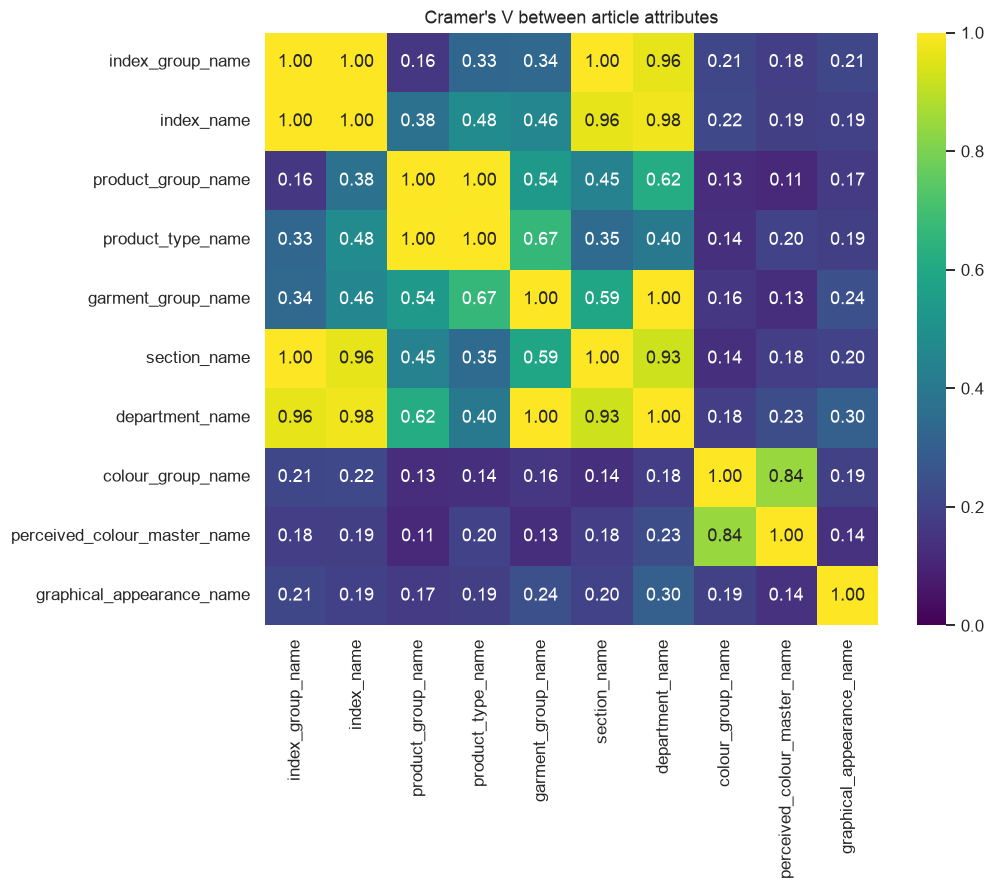

In [22]:
# 6d. Association between categorical article attributes (Cramer's V; 0 = none, 1 = identical info)
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = ((ct - np.outer(ct.sum(1), ct.sum(0)) / ct.values.sum()) ** 2 /
            (np.outer(ct.sum(1), ct.sum(0)) / ct.values.sum())).values.sum()
    n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_, k_ = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_ - 1, r_ - 1)))

acols = ["index_group_name", "index_name", "product_group_name", "product_type_name",
         "garment_group_name", "section_name", "department_name",
         "colour_group_name", "perceived_colour_master_name", "graphical_appearance_name"]
V = pd.DataFrame(index=acols, columns=acols, dtype=float)
for a in acols:
    for b in acols:
        V.loc[a, b] = 1.0 if a == b else cramers_v(articles[a], articles[b])

plt.figure(figsize=(9, 7))
sns.heatmap(V, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Cramer's V between article attributes"); plt.show()

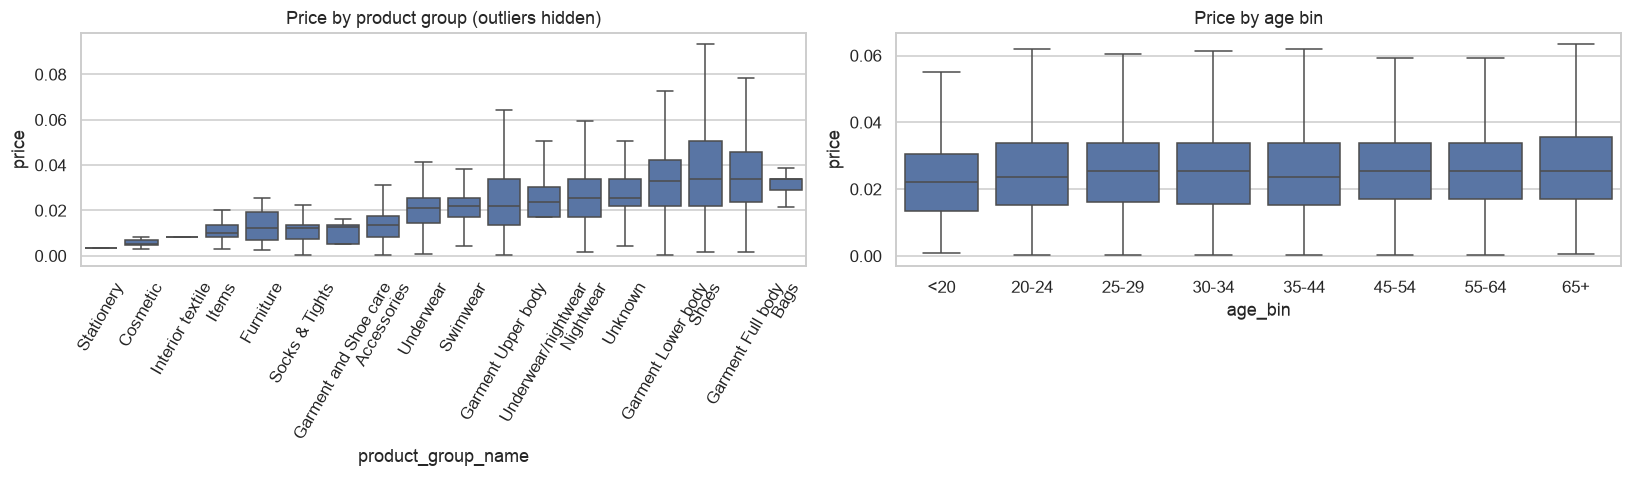

In [23]:
# 6e. Price vs. product group, and price vs. age
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
order = df.groupby("product_group_name")["price"].median().sort_values().index
sns.boxplot(data=df, x="product_group_name", y="price", order=order, ax=ax[0], showfliers=False)
ax[0].tick_params(axis="x", rotation=60); ax[0].set_title("Price by product group (outliers hidden)")
sns.boxplot(data=df, x="age_bin", y="price", ax=ax[1], showfliers=False); ax[1].set_title("Price by age bin")
plt.tight_layout(); plt.show()

## Key insights and challenges

The three tables cover 1.37 million customers, 105,542 articles, and 31.8 million transactions from 2018-09-20 to 2020-09-22. Coverage is strong: 99.3% of customers and 99.1% of articles appear in transactions, with no orphan article IDs, although 995 articles were never sold. Purchases are highly uneven: the median customer made 9 purchases (versus a mean of 23.3), the top 10,000 articles account for 59.6% of transactions, and the customer-item matrix is only 0.01886% dense; 14.3% of transactions in the sampled subset are repeat customer-article purchases, including possible same-day repeats. Customers have a median age of 32, and Ladieswear dominates purchases across age groups, while Divided's share declines with age; product mix differs only modestly by sales channel. Sales also show clear seasonality, especially for swimwear, which peaks in summer, alongside a few sharp volume spikes that may reflect promotions. Several customer and article features are redundant, including FN/Active and nested product classifications, while customer age is largely unrelated to purchase volume. Important challenges are the transaction file's scale, roughly 3.0 million exact duplicate rows that should not be removed without deciding whether they represent separate units, sparse and short customer histories, missing demographic and engagement fields, anomalous zero prices and a highly concentrated postal-code value, and high-cardinality or free-text product attributes. Popularity labels will depend on the chosen time window and can be distorted by seasonality and spikes; article-level models therefore need carefully aggregated features, leakage-safe feature and label periods, explicit handling of unsold/tied articles, and attention to redundant features. Joined analyses based on a one-million-row sample are exploratory and should be validated before drawing definitive conclusions.